# UCS_Trailer: Uniform Cost Search for the Self-Driving Trailer
**ICS 3202 Practical Exercise 3 (Part 3B)**

**Group members**

| Name | Admission No. |
|------|---------------|
| Elvis Mwangi | 184214 |
| Mark Kiplangat | 191241 |
| Mohamed Abdi | 190125 |

---

## 1. The problem

In Part 1 we designed a self-driving trailer agent that has to carry cargo from **Nairobi** to **Kisumu** using Kenya's highway network. Here we actually run the search. We use **Uniform Cost Search (UCS)** on the directed graph and path costs (distances in km) from Part 1.

**Problem formulation (same as Part 1)**

1. **Initial state:** In(Nairobi)
2. **Actions:** Drive(A, B) along an edge that exists in the graph
3. **Transition model:** Result(In(A), Drive(A, B)) = In(B)
4. **Goal test:** Is the state In(Kisumu)?
5. **Path cost:** Sum of the distances (km) of the edges travelled

**How UCS works (as done in class)**

- Keep a **frontier** (priority queue) ordered by the path cost g(n) so far.
- Always **pop the cheapest node** from the frontier and expand it.
- Do the **goal test when a node is popped**, not when it is added. That is what makes UCS optimal, because a cheaper path to the goal could still be sitting in the frontier.
- If we find a **cheaper path to a node already in the frontier**, we update it.
- Keep an **explored set** so we never expand a node twice.

## 2. The directed graph and path costs (from Part 1)

In [1]:
import heapq
import itertools

# Directed graph in the direction of travel (Nairobi -> Kisumu), costs in km.
# graph[A] = {B: distance(A, B), ...}
graph = {
    "Nairobi":   {"Thika": 46, "Naivasha": 92, "Narok": 145},
    "Thika":     {"Murang'a": 46},
    "Murang'a":  {"Nyeri": 62.2},
    "Nyeri":     {"Nyahururu": 104},
    "Nyahururu": {"Nakuru": 63.3},
    "Naivasha":  {"Nakuru": 69.7},
    "Narok":     {"Bomet": 81},
    "Bomet":     {"Kericho": 76.1},
    "Nakuru":    {"Kericho": 110, "Eldoret": 155},
    "Eldoret":   {"Kitale": 74.2, "Kakamega": 88, "Kisumu": 138},
    "Kakamega":  {"Kisumu": 52},
    "Kericho":   {"Kisumu": 84, "Kisii": 87.2},
    "Kisii":     {"Kisumu": 107},
    "Kitale":    {},
    "Kisumu":    {},
}

start, goal = "Nairobi", "Kisumu"

# quick check: print the edge list
n_edges = sum(len(v) for v in graph.values())
print(f"{len(graph)} towns, {n_edges} directed roads\n")
for a, nbrs in graph.items():
    for b, w in nbrs.items():
        print(f"{a:10s} -> {b:10s} {w:>6} km")

15 towns, 19 directed roads

Nairobi    -> Thika          46 km
Nairobi    -> Naivasha       92 km
Nairobi    -> Narok         145 km
Thika      -> Murang'a       46 km
Murang'a   -> Nyeri        62.2 km
Nyeri      -> Nyahururu     104 km
Nyahururu  -> Nakuru       63.3 km
Naivasha   -> Nakuru       69.7 km
Narok      -> Bomet          81 km
Bomet      -> Kericho      76.1 km
Nakuru     -> Kericho       110 km
Nakuru     -> Eldoret       155 km
Eldoret    -> Kitale       74.2 km
Eldoret    -> Kakamega       88 km
Eldoret    -> Kisumu        138 km
Kakamega   -> Kisumu         52 km
Kericho    -> Kisumu         84 km
Kericho    -> Kisii        87.2 km
Kisii      -> Kisumu        107 km


## 3. Uniform Cost Search implementation

The function below follows the class steps. For every iteration it prints:
- the **frontier** before we pop
- the **node expanded** and its cost g(n)
- each **child** that gets added, or updated if we found a cheaper path
- the **explored set**

At the end it rebuilds the path using the `parent` dictionary and returns the total cost.

In [2]:
def ucs(graph, start, goal, verbose=True):
    counter = itertools.count()          # tie-breaker so heapq never compares towns
    frontier = [(0, next(counter), start)]   # (g, tie, node)
    best_g = {start: 0}                  # cheapest cost found so far to each node
    parent = {start: None}               # to rebuild the path
    explored = set()
    step = 0

    while frontier:
        step += 1
        if verbose:
            shown = sorted((round(g, 1), n) for g, _, n in frontier if n not in explored)
            print(f"--- Step {step} ---")
            print("Frontier:", [f"{n}({g})" for g, n in shown])

        g, _, node = heapq.heappop(frontier)

        # skip stale entries (a cheaper path to this node was already expanded)
        if node in explored:
            continue

        if verbose:
            print(f"Pop (lowest cost): {node}  g = {round(g, 1)} km")

        # goal test on POP (this is what guarantees optimality)
        if node == goal:
            path = []
            while node is not None:
                path.append(node)
                node = parent[node]
            path.reverse()
            if verbose:
                print(f"\nGOAL REACHED: {goal} with cost {round(g, 1)} km\n")
            return path, g, step

        explored.add(node)

        # expand
        for child, w in graph[node].items():
            new_g = g + w
            if child in explored:
                continue
            if child not in best_g:
                best_g[child] = new_g
                parent[child] = node
                heapq.heappush(frontier, (new_g, next(counter), child))
                if verbose:
                    print(f"   add    {child:10s} g = {node}({round(g,1)}) + {w} = {round(new_g, 1)}")
            elif new_g < best_g[child]:
                old_g = best_g[child]
                best_g[child] = new_g
                parent[child] = node
                heapq.heappush(frontier, (new_g, next(counter), child))
                if verbose:
                    print(f"   update {child:10s} cheaper path found: {round(new_g, 1)} (was {round(old_g, 1)})")
            else:
                if verbose:
                    print(f"   skip   {child:10s} {round(new_g, 1)} is not cheaper than {round(best_g[child], 1)}")
        if verbose:
            print("Explored:", sorted(explored), "\n")

    return None, float("inf"), step

## 4. Running the search from Nairobi to Kisumu

In [3]:
path, cost, steps = ucs(graph, start, goal)

--- Step 1 ---
Frontier: ['Nairobi(0)']
Pop (lowest cost): Nairobi  g = 0 km
   add    Thika      g = Nairobi(0) + 46 = 46
   add    Naivasha   g = Nairobi(0) + 92 = 92
   add    Narok      g = Nairobi(0) + 145 = 145
Explored: ['Nairobi'] 

--- Step 2 ---
Frontier: ['Thika(46)', 'Naivasha(92)', 'Narok(145)']
Pop (lowest cost): Thika  g = 46 km
   add    Murang'a   g = Thika(46) + 46 = 92
Explored: ['Nairobi', 'Thika'] 

--- Step 3 ---
Frontier: ["Murang'a(92)", 'Naivasha(92)', 'Narok(145)']
Pop (lowest cost): Naivasha  g = 92 km
   add    Nakuru     g = Naivasha(92) + 69.7 = 161.7
Explored: ['Nairobi', 'Naivasha', 'Thika'] 

--- Step 4 ---
Frontier: ["Murang'a(92)", 'Narok(145)', 'Nakuru(161.7)']
Pop (lowest cost): Murang'a  g = 92 km
   add    Nyeri      g = Murang'a(92) + 62.2 = 154.2
Explored: ["Murang'a", 'Nairobi', 'Naivasha', 'Thika'] 

--- Step 5 ---
Frontier: ['Narok(145)', 'Nyeri(154.2)', 'Nakuru(161.7)']
Pop (lowest cost): Narok  g = 145 km
   add    Bomet      g = Narok(145)

## 5. Optimal path and cost

In [4]:
print("Optimal path :", " -> ".join(path))
print("Total cost    :", round(cost, 1), "km")
print("Nodes popped  :", steps)
print()
print("Leg by leg:")
total = 0
for a, b in zip(path, path[1:]):
    w = graph[a][b]
    total += w
    print(f"  {a:10s} -> {b:10s} {w:>6} km   (running total {round(total, 1)} km)")

Optimal path : Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
Total cost    : 355.7 km
Nodes popped  : 12

Leg by leg:
  Nairobi    -> Naivasha       92 km   (running total 92 km)
  Naivasha   -> Nakuru       69.7 km   (running total 161.7 km)
  Nakuru     -> Kericho       110 km   (running total 271.7 km)
  Kericho    -> Kisumu         84 km   (running total 355.7 km)


## 6. Checking the answer
To be sure UCS is right, we list **every possible route** from Nairobi to Kisumu using depth-first enumeration and compare their costs. The cheapest one should match what UCS returned.

In [5]:
def all_paths(graph, node, goal, visited=None):
    visited = (visited or []) + [node]
    if node == goal:
        yield visited
        return
    for nxt in graph[node]:
        if nxt not in visited:
            yield from all_paths(graph, nxt, goal, visited)

def path_cost(p):
    return sum(graph[a][b] for a, b in zip(p, p[1:]))

routes = sorted(((path_cost(p), p) for p in all_paths(graph, start, goal)), key=lambda x: x[0])
print(f"{len(routes)} possible routes from {start} to {goal}:\n")
for c, p in routes:
    print(f"{round(c, 1):>7} km   {' -> '.join(p)}")

assert abs(routes[0][0] - cost) < 1e-9 and routes[0][1] == path
print("\nUCS answer matches the cheapest route found by brute force.")

10 possible routes from Nairobi to Kisumu:

  355.7 km   Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
  386.1 km   Nairobi -> Narok -> Bomet -> Kericho -> Kisumu
  454.7 km   Nairobi -> Naivasha -> Nakuru -> Eldoret -> Kisumu
  456.7 km   Nairobi -> Naivasha -> Nakuru -> Eldoret -> Kakamega -> Kisumu
  465.9 km   Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisii -> Kisumu
  496.3 km   Nairobi -> Narok -> Bomet -> Kericho -> Kisii -> Kisumu
  515.5 km   Nairobi -> Thika -> Murang'a -> Nyeri -> Nyahururu -> Nakuru -> Kericho -> Kisumu
  614.5 km   Nairobi -> Thika -> Murang'a -> Nyeri -> Nyahururu -> Nakuru -> Eldoret -> Kisumu
  616.5 km   Nairobi -> Thika -> Murang'a -> Nyeri -> Nyahururu -> Nakuru -> Eldoret -> Kakamega -> Kisumu
  625.7 km   Nairobi -> Thika -> Murang'a -> Nyeri -> Nyahururu -> Nakuru -> Kericho -> Kisii -> Kisumu

UCS answer matches the cheapest route found by brute force.


## 7. Visualising the traversal

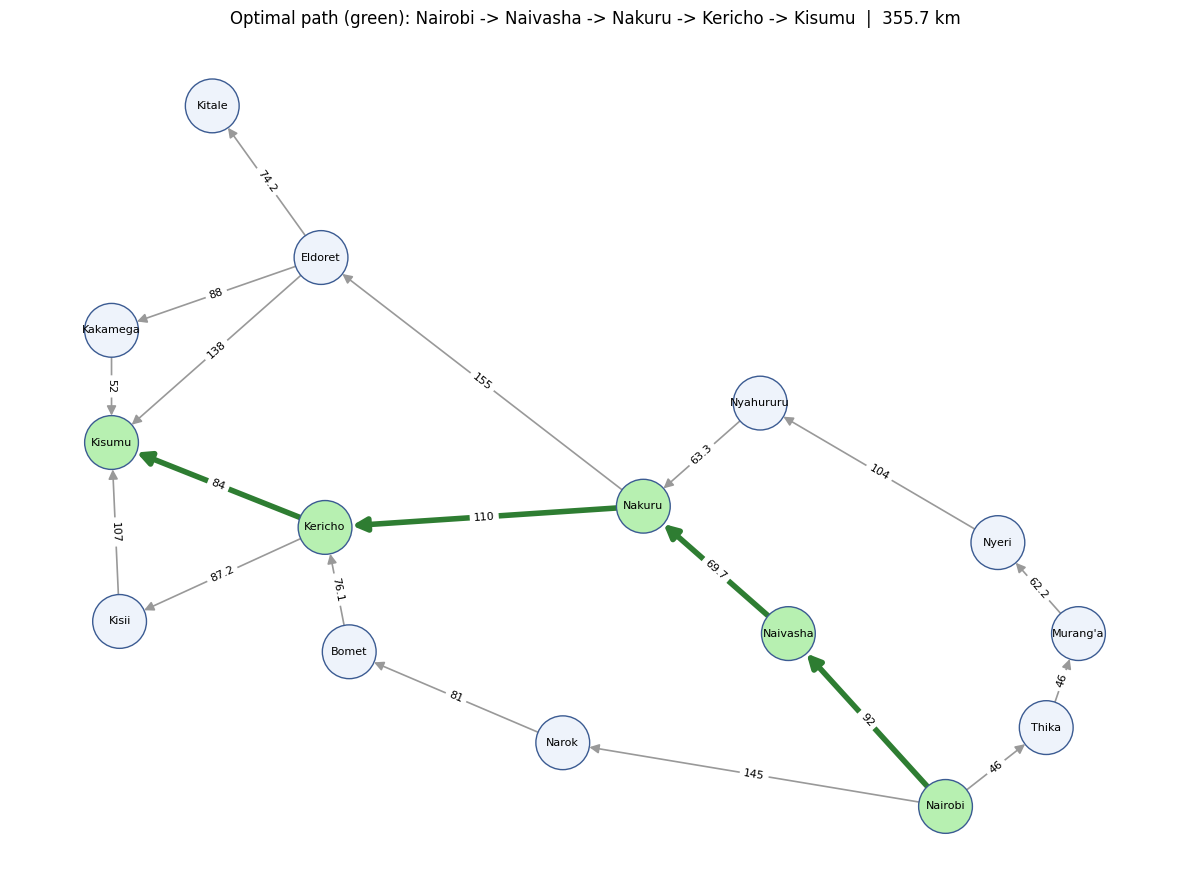

In [6]:
import matplotlib.pyplot as plt
import networkx as nx

# rough (longitude, latitude) of each town so the graph looks like a map of Kenya
pos = {
    "Nairobi": (36.82, -1.29), "Thika": (37.07, -1.03), "Murang'a": (37.15, -0.72),
    "Nyeri": (36.95, -0.42), "Nyahururu": (36.36, 0.04), "Naivasha": (36.43, -0.72),
    "Nakuru": (36.07, -0.30), "Narok": (35.87, -1.08), "Bomet": (35.34, -0.78),
    "Kericho": (35.28, -0.37), "Eldoret": (35.27, 0.52), "Kitale": (35.0, 1.02),
    "Kakamega": (34.75, 0.28), "Kisii": (34.77, -0.68), "Kisumu": (34.75, -0.09),
}

G = nx.DiGraph()
for a, nbrs in graph.items():
    for b, w in nbrs.items():
        G.add_edge(a, b, weight=w)

opt_edges = list(zip(path, path[1:]))
other_edges = [e for e in G.edges if e not in opt_edges]

fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx_edges(G, pos, edgelist=other_edges, edge_color="#999999", arrows=True,
                       arrowsize=14, width=1.2, ax=ax, node_size=1500)
nx.draw_networkx_edges(G, pos, edgelist=opt_edges, edge_color="#2e7d32", arrows=True,
                       arrowsize=20, width=4, ax=ax, node_size=1500)
node_colors = ["#b7f0b1" if n in path else "#eef3fb" for n in G.nodes]
nx.draw_networkx_nodes(G, pos, node_color=node_colors, edgecolors="#3b5b92", node_size=1500, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
nx.draw_networkx_edge_labels(G, pos, edge_labels={(a, b): d["weight"] for a, b, d in G.edges(data=True)},
                             font_size=8, ax=ax)
ax.set_title(f"Optimal path (green): {' -> '.join(path)}  |  {round(cost, 1)} km")
ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Conclusion

- UCS expanded towns in order of their path cost from Nairobi, and only stopped when **Kisumu was popped** from the frontier.
- Kisumu entered the frontier at 355.7 km when Kericho was expanded. Later, when Eldoret was expanded, the Eldoret route to Kisumu (454.7 km) was skipped because it was not cheaper, so the Kericho route stayed.
- **Optimal path: Nairobi → Naivasha → Nakuru → Kericho → Kisumu**
- **Total path cost: 92 + 69.7 + 110 + 84 = 355.7 km**

UCS is **complete** (it always finds a solution when one exists, because every road has a positive cost) and **optimal** (it always returns the cheapest path), which makes it a good fit for a trailer that wants to save fuel and time.

## 9. Evidence of Group Work

### Meeting minutes

| | |
|---|---|
| **Date** | 05/11/2026 |
| **Venue / platform** | Students Center |
| **Present** | Elvis Mwangi, Mark Kiplangat, Mohamed Abdi |
| **Absent (with apologies)** | None, all members present |

**Agenda:** Implementing Uniform Cost Search for the trailer (Nairobi to Kisumu) in Python.

**Discussion and contributions:**

| Member | Contribution |
|--------|--------------|
| Elvis Mwangi | Wrote the graph dictionary and the main UCS function (frontier, explored set, goal test on pop) |
| Mark Kiplangat | Wrote the step by step trace printing, path reconstruction using the parent dictionary, and the leg by leg cost breakdown |
| Mohamed Abdi | Wrote the brute force check of all routes and the map visualisation of the optimal path |
| All members | Tested the notebook together and agreed on the final answer |

**Meeting closed at:** 5pm